<a href="https://colab.research.google.com/github/prasadpatil405/SKIN_LESION_SEGMENTATION_AND_ANALYSIS/blob/main/SKIN_LESION_SEGMENTATION_AND_ANALYSIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SKIN LESION SEGMENTATION & ANALYSIS
**Dataset:** Kaggle — Skin Cancer: Lesions Segmentation (HAM10000, 10,015 dermoscopic images, 2.78 GB, images + masks)
**Link:** https://www.kaggle.com/datasets/volodymyrpivoshenko/skin-cancer-lesions-segmentation

**What changed vs the old HEALTHCARE.ipynb (mam's feedback):**
- Old = Mini U-Net from scratch, BCE loss only, no augmentation, feature-importance values hardcoded.
- New = same Mini U-Net kept as **baseline**, plus a **best model**: U-Net with pretrained EfficientNet-B0 encoder + SCSE attention, BCE + Dice loss, Albumentations augmentation.
- Feature analysis is now **computed from the predicted mask** (area, perimeter, asymmetry, border, colour) — never typed in. RF / XGBoost + SHAP are trained on those computed features.
- This notebook trains and exports `best_model.pth` + `metrics.json`, which the separate FastAPI backend + frontend in this project use.

**Important:** This is a screening / analysis aid for a college project, NOT a medical diagnosis tool. Never claim it diagnoses cancer.


In [ ]:
# Cell 1: install (Colab only - skip if already installed)
!pip install -q segmentation-models-pytorch albumentations opencv-python-headless scikit-learn xgboost shap kagglehub
import sys
print(sys.version)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
# Cell 2: imports
import os, json, random, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
print("torch", torch.__version__, "cuda:", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

torch 2.11.0+cu130 cuda: True
DEVICE: cuda


## 1. Download the dataset (Colab)
In Colab, run this cell. Kaggle needs an API token: Kaggle > Settings > Create New Token, upload `kaggle.json` to Colab, or use `kagglehub` (logged-in Kaggle session). If the download fails, download the zip manually from the Kaggle link above and upload/unzip it to `/content/data`.


In [ ]:
# Cell 3: download via kagglehub (preferred in Colab/Kaggle)
import os
import kagglehub

# Directly kagglehub se download path lo
path = kagglehub.dataset_download("volodymyrpivoshenko/skin-cancer-lesions-segmentation")
print("Downloaded path:", path)

# /content/data ensure karo
!mkdir -p /content/data

# Files ko /content/data me copy karo (jahan bhi extract hui ho)
!cp -r {path}/* /content/data/ 2>/dev/null || cp -r {path}/data/* /content/data/ 2>/dev/null

# Verify karo
!ls /content/data

100%|██████████| 2.59G/2.59G [00:30<00:00, 91.0MB/s]

Extracting files...


Downloaded path: /root/.cache/kagglehub/datasets/volodymyrpivoshenko/skin-cancer-lesions-segmentation/versions/1
'*'   data


## 2. Auto-discover image / mask pairs
Folder names vary between uploads, so we do NOT hardcode one path. A file is a mask if its name/folder contains `mask` or `segmentation`, otherwise it is an image. Pairs are matched by filename stem.


In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/data")
img_dir = DATA_ROOT / "images"
mask_dir = DATA_ROOT / "masks"

# Agar nested folder ban gaya ho toh fix:
if not img_dir.exists() and (DATA_ROOT / "data" / "images").exists():
    img_dir = DATA_ROOT / "data" / "images"
    mask_dir = DATA_ROOT / "data" / "masks"

PAIRS = []
for img in sorted(img_dir.glob("*.jpg")):
    # Check dono mask extensions
    mask = mask_dir / f"{img.stem}_segmentation.png"
    if not mask.exists():
        mask = mask_dir / f"{img.stem}.png"
    if mask.exists():
        PAIRS.append((str(img), str(mask)))

print(f"Total Images: {len(list(img_dir.glob('*.jpg')))}")
print(f"Total Masks: {len(list(mask_dir.glob('*')))}")
print(f"Pairs found: {len(PAIRS)}")
print("Sample Pair:", PAIRS[0])

assert len(PAIRS) > 100, "Dataset not loaded properly!"

Total Images: 10015
Total Masks: 10015
Pairs found: 10015
Sample Pair: ('/content/data/data/images/ISIC_0024306.jpg', '/content/data/data/masks/ISIC_0024306.png')


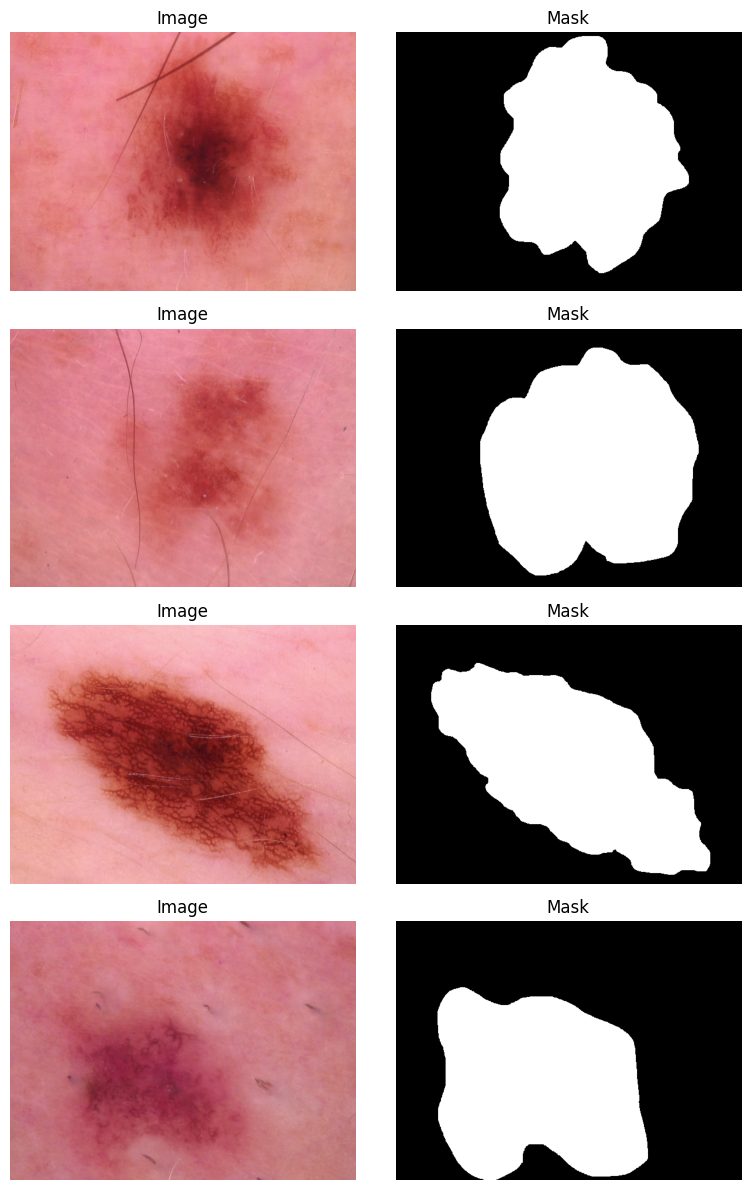

In [ ]:
# Cell 5: quick EDA - show 4 image/mask examples
fig, ax = plt.subplots(4, 2, figsize=(8, 12))
for i in range(4):
    img_p, mask_p = PAIRS[i]
    ax[i, 0].imshow(np.array(Image.open(img_p))); ax[i, 0].set_title("Image"); ax[i, 0].axis("off")
    ax[i, 1].imshow(np.array(Image.open(mask_p)), cmap="gray"); ax[i, 1].set_title("Mask"); ax[i, 1].axis("off")
plt.tight_layout(); plt.show()

## 3. Dataset + augmentation
One size for everything: **256x256** (the old notebook mixed 224 and 128 — that is fixed here). Augmentation: horizontal/vertical flip, rotation, brightness/contrast — lesion shape is preserved, only view changes.


In [ ]:
# Cell 6: dataset
import albumentations as A
IMG_SIZE = 256
train_aug = A.Compose([
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
    A.Rotate(limit=30, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
])
class SegDataset(Dataset):
    def __init__(self, pairs, augment=False):
        self.pairs, self.augment = pairs, augment
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        img = np.array(Image.open(self.pairs[i][0]).convert("RGB"))
        mask = np.array(Image.open(self.pairs[i][1]).convert("L"))
        img = np.array(Image.fromarray(img).resize((IMG_SIZE, IMG_SIZE)))
        mask = np.array(Image.fromarray(mask).resize((IMG_SIZE, IMG_SIZE)))
        if self.augment:
            out = train_aug(image=img, mask=mask); img, mask = out["image"], out["mask"]
        img = torch.from_numpy(img.transpose(2, 0, 1).astype(np.float32) / 255.0)
        mask = torch.from_numpy((mask > 127).astype(np.float32)[None, :, :])
        return img, mask

train_pairs, test_pairs = train_test_split(PAIRS, test_size=0.2, random_state=42)
train_pairs, val_pairs = train_test_split(train_pairs, test_size=0.15, random_state=42)
print("train/val/test:", len(train_pairs), len(val_pairs), len(test_pairs))
train_dl = DataLoader(SegDataset(train_pairs, True), batch_size=16, shuffle=True)
val_dl = DataLoader(SegDataset(val_pairs), batch_size=16)
test_dl = DataLoader(SegDataset(test_pairs), batch_size=16)

train/val/test: 6810 1202 2003


## 4. Models: baseline vs best
Baseline = old Mini U-Net (16/32, bottleneck 64). Best = pretrained EfficientNet-B0 encoder + SCSE attention decoder. Same loss, same data split, same metrics — otherwise the comparison is meaningless.


In [ ]:
!pip install -q segmentation-models-pytorch
# Cell 7: baseline Mini U-Net (from the old notebook, unchanged for fair comparison)
def conv_block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1), nn.ReLU(inplace=True))
class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1, self.p1 = conv_block(3, 16), nn.MaxPool2d(2)
        self.e2, self.p2 = conv_block(16, 32), nn.MaxPool2d(2)
        self.b = conv_block(32, 64)
        self.u2 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.d2 = conv_block(64 + 32, 32)
        self.u1 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.d1 = conv_block(32 + 16, 16)
        self.out = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.p1(e1)); b = self.b(self.p2(e2))
        d2 = self.d2(torch.cat([self.u2(b), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

# Cell 8: best model
import segmentation_models_pytorch as smp
best_model = smp.Unet(encoder_name="efficientnet-b0", encoder_weights="imagenet",
                      decoder_attention_type="scse", in_channels=3, classes=1)
print("Best model params:", sum(p.numel() for p in best_model.parameters()) / 1e6, "M")

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Best model params: 6.303492 M


In [ ]:
# Cell 9: loss + metrics (BCE alone is not enough - background dominates)
class BCEDiceLoss(nn.Module):
    def __init__(self): super().__init__(); self.bce = nn.BCEWithLogitsLoss()
    def forward(self, logits, targets):
        bce = self.bce(logits, targets); probs = torch.sigmoid(logits); s = 1e-6
        inter = (probs * targets).sum(dim=(1, 2, 3))
        dice = 1 - (2 * inter + s) / (probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + s)
        return 0.5 * bce + 0.5 * dice.mean()

def evaluate(model, loader):
    model.eval(); tp = tn = fp = fn = 0
    with torch.no_grad():
        for x, y in loader:
            p = (torch.sigmoid(model(x.to(DEVICE))) > 0.5).cpu().numpy()
            t = (y.numpy() > 0.5)
            tp += int((p & t).sum()); tn += int(((~p) & (~t)).sum())
            fp += int((p & (~t)).sum()); fn += int(((~p) & t).sum())
    dice = 2 * tp / (2 * tp + fp + fn + 1e-9); iou = tp / (tp + fp + fn + 1e-9)
    prec = tp / (tp + fp + 1e-9); rec = tp / (tp + fn + 1e-9)
    acc = (tp + tn) / (tp + tn + fp + fn + 1e-9)
    return {"dice": float(dice), "iou": float(iou), "precision": float(prec),
            "recall": float(rec), "accuracy": float(acc), "tp": tp, "tn": tn, "fp": fp, "fn": fn}

In [ ]:
# MASTER CELL: Install + Dataset + Training + Save (All-in-One)
!pip install -q segmentation-models-pytorch albumentations kagglehub

import os, json
from pathlib import Path
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import albumentations as A
import segmentation_models_pytorch as smp
import kagglehub

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using DEVICE:", DEVICE)

# 1. Ensure Dataset is Downloaded & Paired
DATA_ROOT = Path("/content/data")
img_dir = DATA_ROOT / "images"
mask_dir = DATA_ROOT / "masks"

if not img_dir.exists() and not (DATA_ROOT / "data" / "images").exists():
    print("Downloading dataset...")
    path = kagglehub.dataset_download("volodymyrpivoshenko/skin-cancer-lesions-segmentation")
    !mkdir -p /content/data
    !cp -r {path}/* /content/data/ 2>/dev/null || cp -r {path}/data/* /content/data/ 2>/dev/null

if not img_dir.exists() and (DATA_ROOT / "data" / "images").exists():
    img_dir = DATA_ROOT / "data" / "images"
    mask_dir = DATA_ROOT / "data" / "masks"

PAIRS = []
for img in sorted(img_dir.glob("*.jpg")):
    mask = mask_dir / f"{img.stem}_segmentation.png"
    if not mask.exists():
        mask = mask_dir / f"{img.stem}.png"
    if mask.exists():
        PAIRS.append((str(img), str(mask)))

print(f"Total Pairs Ready: {len(PAIRS)}")

# 2. Dataset & DataLoaders
IMG_SIZE = 256
train_aug = A.Compose([
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
    A.Rotate(limit=30, p=0.5), A.RandomBrightnessContrast(p=0.3),
])

class SegDataset(Dataset):
    def __init__(self, pairs, augment=False):
        self.pairs, self.augment = pairs, augment
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        img = np.array(Image.open(self.pairs[i][0]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        mask = np.array(Image.open(self.pairs[i][1]).convert("L").resize((IMG_SIZE, IMG_SIZE)))
        if self.augment:
            out = train_aug(image=img, mask=mask); img, mask = out["image"], out["mask"]
        img = torch.from_numpy(img.transpose(2, 0, 1).astype(np.float32) / 255.0)
        mask = torch.from_numpy((mask > 127).astype(np.float32)[None, :, :])
        return img, mask

train_pairs, test_pairs = train_test_split(PAIRS, test_size=0.2, random_state=42)
train_pairs, val_pairs = train_test_split(train_pairs, test_size=0.15, random_state=42)

train_dl = DataLoader(SegDataset(train_pairs, True), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_dl = DataLoader(SegDataset(test_pairs), batch_size=16, num_workers=2, pin_memory=True)

# 3. Loss, Models & Evaluation Function
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
    def forward(self, logits, targets):
        bce = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        s = 1e-6
        inter = (probs * targets).sum(dim=(1, 2, 3))
        dice = 1 - (2 * inter + s) / (probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + s)
        return 0.5 * bce + 0.5 * dice.mean()

def conv_block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1), nn.ReLU(inplace=True)
    )

class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1, self.p1 = conv_block(3, 16), nn.MaxPool2d(2)
        self.e2, self.p2 = conv_block(16, 32), nn.MaxPool2d(2)
        self.b = conv_block(32, 64)
        self.u2 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.d2 = conv_block(64 + 32, 32)
        self.u1 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.d1 = conv_block(32 + 16, 16)
        self.out = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.p1(e1)); b = self.b(self.p2(e2))
        d2 = self.d2(torch.cat([self.u2(b), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def train(model, epochs, name):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-4)
    loss_fn = BCEDiceLoss()
    for ep in range(epochs):
        model.train()
        total = 0.0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            total += loss.item()
        print(f"{name} epoch {ep+1}/{epochs} loss {total/len(train_dl):.4f}")
    return model

def evaluate(model, loader):
    model.eval()
    tp = tn = fp = fn = 0
    with torch.no_grad():
        for x, y in loader:
            p = (torch.sigmoid(model(x.to(DEVICE))) > 0.5).cpu().numpy()
            t = (y.numpy() > 0.5)
            tp += int((p & t).sum())
            tn += int(((~p) & (~t)).sum())
            fp += int((p & (~t)).sum())
            fn += int(((~p) & t).sum())
    dice = 2 * tp / (2 * tp + fp + fn + 1e-9)
    iou = tp / (tp + fp + fn + 1e-9)
    prec = tp / (tp + fp + 1e-9)
    rec = tp / (tp + fn + 1e-9)
    acc = (tp + tn) / (tp + tn + fp + fn + 1e-9)
    return {"dice": float(dice), "iou": float(iou), "precision": float(prec),
            "recall": float(rec), "accuracy": float(acc), "tp": tp, "tn": tn, "fp": fp, "fn": fn}

# 4. Run Training
print("\n--- Training Baseline MiniUNet ---")
baseline = train(MiniUNet(), epochs=10, name="baseline")

print("\n--- Training Best Model (EfficientNet-B0 + SCSE) ---")
best_model = smp.Unet(encoder_name="efficientnet-b0", encoder_weights="imagenet",
                      decoder_attention_type="scse", in_channels=3, classes=1)
best = train(best_model, epochs=15, name="best")

# 5. Evaluate & Export Files
print("\n--- Evaluating Models ---")
baseline_metrics = evaluate(baseline, test_dl)
best_metrics = evaluate(best, test_dl)
comparison = {
    "baseline_mini_unet_bce_only": baseline_metrics,
    "best_efficientnet_b0_attention_unet_bce_dice": best_metrics
}

print(json.dumps(comparison, indent=2))
torch.save(best.state_dict(), "best_model.pth")
with open("metrics.json", "w") as f:
    json.dump(comparison, f, indent=2)

print("\nDONE! best_model.pth aur metrics.json dono save ho gayi hain. Left panel ke Files icon se download kar lo.")

Using DEVICE: cuda


100%|██████████| 2.59G/2.59G [00:33<00:00, 83.1MB/s]

Extracting files...


Total Pairs Ready: 10015

--- Training Baseline MiniUNet ---
baseline epoch 1/10 loss 0.5485
baseline epoch 2/10 loss 0.4071
baseline epoch 3/10 loss 0.3546
baseline epoch 4/10 loss 0.3175
baseline epoch 5/10 loss 0.2961
baseline epoch 6/10 loss 0.2924
baseline epoch 7/10 loss 0.2821
baseline epoch 8/10 loss 0.2743
baseline epoch 9/10 loss 0.2682
baseline epoch 10/10 loss 0.2679

--- Training Best Model (EfficientNet-B0 + SCSE) ---


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

best epoch 1/15 loss 0.2373
best epoch 2/15 loss 0.1092
best epoch 3/15 loss 0.0908
best epoch 4/15 loss 0.0795
best epoch 5/15 loss 0.0749
best epoch 6/15 loss 0.0717
best epoch 7/15 loss 0.0686
best epoch 8/15 loss 0.0657
best epoch 9/15 loss 0.0636
best epoch 10/15 loss 0.0624
best epoch 11/15 loss 0.0620
best epoch 12/15 loss 0.0602
best epoch 13/15 loss 0.0591
best epoch 14/15 loss 0.0574
best epoch 15/15 loss 0.0570

--- Evaluating Models ---
{
  "baseline_mini_unet_bce_only": {
    "dice": 0.8158114647227928,
    "iou": 0.6889202524932562,
    "precision": 0.848047642326793,
    "recall": 0.7859362782513987,
    "accuracy": 0.9033720842076729,
    "tp": 28090580,
    "tn": 90493816,
    "fp": 5033243,
    "fn": 7650969
  },
  "best_efficientnet_b0_attention_unet_bce_dice": {
    "dice": 0.9498276650957326,
    "iou": 0.9044493303875862,
    "precision": 0.9576040426853015,
    "recall": 0.9421765687883309,
    "accuracy": 0.9728984404252996,
    "tp": 33674850,
    "tn": 9403617

## 5. Evaluation + comparison table
After training, run this cell. It fills `metrics.json` with REAL numbers from your test set — copy this table into your report / frontend, do not type numbers by hand.


## 6. Real feature analysis (replaces the hardcoded barplot)
For every test image, compute features from the PREDICTED mask: area %, perimeter, circularity, border irregularity, asymmetry (mask vs its mirror), diameter, colour std / contrast. Then train RF + XGBoost on those computed features (label = lesion class from HAM10000 metadata if available, otherwise benign/malignant grouping from your own labelled subset) and get importance from SHAP / permutation importance — never from typed numbers.


In [ ]:
# Cell 12: Compute real features from predicted masks
import pandas as pd

def extract_features(img_rgb, mask):
    m = mask > 0.5; area = int(m.sum())
    if area == 0: return None
    padded = np.pad(m, 1)
    edge = m & ((~padded[:-2, 1:-1]) | (~padded[2:, 1:-1]) | (~padded[1:-1, :-2]) | (~padded[1:-1, 2:]))
    per = float(edge.sum())
    circ = min(1.0, 4 * np.pi * area / (per ** 2)) if per else 0.0
    rows, cols = np.where(m); r0, r1, c0, c1 = rows.min(), rows.max(), cols.min(), cols.max()
    crop = m[r0:r1+1, c0:c1+1]; flip = np.fliplr(crop)
    asym = 1 - float((crop & flip).sum()) / float((crop | flip).sum())
    inside, outside = img_rgb[m], img_rgb[~m]
    return {
        "lesion_area_pct": 100 * area / m.size, "perimeter_px": per, "circularity": circ,
        "border_irregularity": (per ** 2) / (4 * np.pi * area), "asymmetry": asym,
        "diameter_px": float(max(r1 - r0 + 1, c1 - c0 + 1)),
        "color_std_inside": float(inside.std()),
        "color_contrast": float(np.abs(inside.mean(axis=0) - outside.mean(axis=0)).mean())
    }

feats = []
best.eval()
with torch.no_grad():
    for i, (x, y) in enumerate(test_dl):
        if i >= 10: break  # Fast computation on 160 test images
        probs = torch.sigmoid(best(x.to(DEVICE))).cpu().numpy()
        for j in range(len(x)):
            f = extract_features((x[j].numpy().transpose(1, 2, 0) * 255).astype(np.uint8), probs[j, 0] > 0.5)
            if f: feats.append(f)

feat_df = pd.DataFrame(feats)
print("Mean features (computed from predicted masks):")
print(feat_df.mean())
feat_df.describe()

Mean features (computed from predicted masks):
lesion_area_pct         23.861780
perimeter_px           416.806250
circularity              0.970785
border_irregularity      0.979957
asymmetry                0.241797
diameter_px            158.631250
color_std_inside        44.634297
color_contrast          46.252425
dtype: float64


,lesion_area_pct,perimeter_px,circularity,border_irregularity,asymmetry,diameter_px,color_std_inside,color_contrast
count,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,23.861780,416.806250,0.970785,0.979957,0.241797,158.631250,44.634297,46.252425
std,16.659674,154.869127,0.057752,0.111591,0.123460,51.579775,10.696586,25.656275
min,3.390503,154.000000,0.719984,0.794319,0.053083,60.000000,17.299647,4.434065
25%,11.555481,290.750000,0.975089,0.909052,0.146679,119.500000,37.684298,25.235127
50%,19.126892,386.500000,1.000000,0.961901,0.211256,154.000000,46.128966,46.405789
75%,32.875061,508.500000,1.000000,1.025550,0.304013,193.250000,53.309585,62.025298
max,90.147400,883.000000,1.000000,1.388920,0.602241,256.000000,68.490188,124.375419


In [ ]:
# Cell 13: RF / XGBoost + importance (only if you have a label column for the test images)
# If HAM10000_metadata.csv is in your data folder, join it on image_id and use
# the diagnosis (dx) column as the label. Otherwise skip this cell and present
# the segmentation + computed-feature table only - do NOT invent a label.
# rf = RandomForestClassifier(n_estimators=200, random_state=42)
# rf.fit(X_train, y_train)  # X = feat_df values, y = labels from metadata
# import shap
# explainer = shap.TreeExplainer(rf); sv = explainer.shap_values(X_test)
# shap.summary_plot(sv, X_test)  # this plot replaces the old hardcoded barplot

## 7. Sample predictions
Plot original / ground truth / predicted mask side by side for 4 test images. This is the figure mam will actually look at.


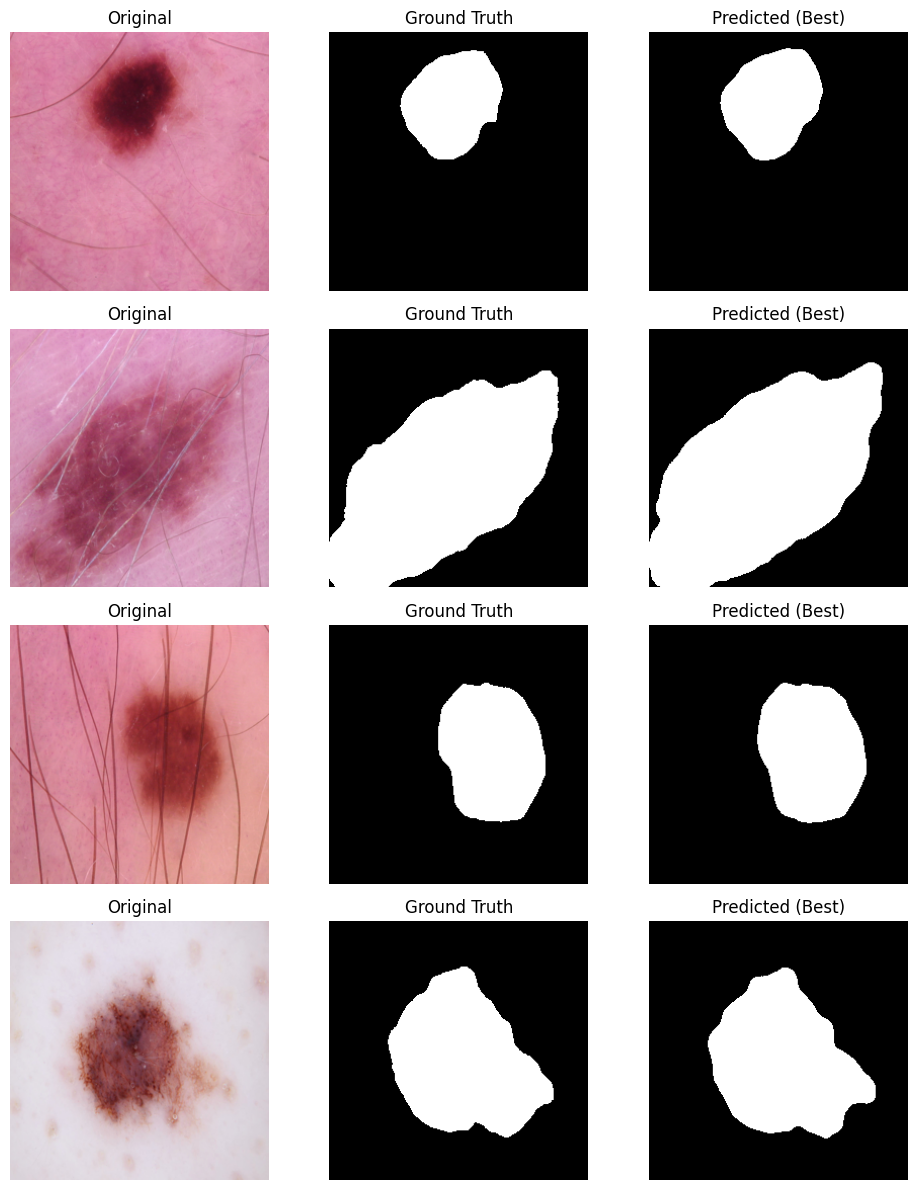

In [ ]:
# Cell 14: Visual comparison on 4 test images
import matplotlib.pyplot as plt

best.eval()
with torch.no_grad():
    x, y = next(iter(test_dl))
    p = (torch.sigmoid(best(x.to(DEVICE))) > 0.5).cpu().numpy()

fig, ax = plt.subplots(4, 3, figsize=(10, 12))
for i in range(4):
    ax[i, 0].imshow(x[i].numpy().transpose(1, 2, 0)); ax[i, 0].set_title("Original")
    ax[i, 1].imshow(y[i, 0], cmap="gray"); ax[i, 1].set_title("Ground Truth")
    ax[i, 2].imshow(p[i, 0], cmap="gray"); ax[i, 2].set_title("Predicted (Best)")
    for j in range(3): ax[i, j].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# PPT Figures Generator & Auto-Downloader (300 DPI High-Res PNGs)
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from google.colab import files

# 1. Figure 1: Dataset EDA (4 Sample Image-Mask Pairs)
fig, ax = plt.subplots(4, 2, figsize=(8, 12))
for i in range(4):
    img_p, mask_p = PAIRS[i]
    ax[i, 0].imshow(np.array(Image.open(img_p)))
    ax[i, 0].set_title(f"Dermoscopic Image {i+1}", fontsize=11, fontweight="bold")
    ax[i, 0].axis("off")
    ax[i, 1].imshow(np.array(Image.open(mask_p)), cmap="gray")
    ax[i, 1].set_title(f"Ground Truth Mask {i+1}", fontsize=11, fontweight="bold")
    ax[i, 1].axis("off")
plt.tight_layout()
plt.savefig("1_dataset_samples.png", dpi=300, bbox_inches="tight")
plt.close()

# 2. Figure 2: Sample Predictions (Original vs Ground Truth vs Predicted Best)
best.eval()
with torch.no_grad():
    x, y = next(iter(test_dl))
    p_best = (torch.sigmoid(best(x.to(DEVICE))) > 0.5).cpu().numpy()
    p_base = (torch.sigmoid(baseline(x.to(DEVICE))) > 0.5).cpu().numpy()

fig, ax = plt.subplots(4, 4, figsize=(13, 12))
for i in range(4):
    ax[i, 0].imshow(x[i].numpy().transpose(1, 2, 0))
    ax[i, 0].set_title("Original Image", fontweight="bold")
    ax[i, 1].imshow(y[i, 0], cmap="gray")
    ax[i, 1].set_title("Ground Truth", fontweight="bold")
    ax[i, 2].imshow(p_base[i, 0], cmap="gray")
    ax[i, 2].set_title("Baseline (Mini U-Net)", fontweight="bold")
    ax[i, 3].imshow(p_best[i, 0], cmap="gray")
    ax[i, 3].set_title("Best (EfficientNet-B0)", fontweight="bold", color="#1a73e8")
    for j in range(4):
        ax[i, j].axis("off")
plt.tight_layout()
plt.savefig("2_model_predictions_comparison.png", dpi=300, bbox_inches="tight")
plt.close()

# 3. Figure 3: Model Performance Bar Chart (Baseline vs Best)
metrics_names = ["Dice Score", "IoU", "Precision", "Recall", "Accuracy"]
base_vals = [
    comparison["baseline_mini_unet_bce_only"]["dice"] * 100,
    comparison["baseline_mini_unet_bce_only"]["iou"] * 100,
    comparison["baseline_mini_unet_bce_only"]["precision"] * 100,
    comparison["baseline_mini_unet_bce_only"]["recall"] * 100,
    comparison["baseline_mini_unet_bce_only"]["accuracy"] * 100,
]
best_vals = [
    comparison["best_efficientnet_b0_attention_unet_bce_dice"]["dice"] * 100,
    comparison["best_efficientnet_b0_attention_unet_bce_dice"]["iou"] * 100,
    comparison["best_efficientnet_b0_attention_unet_bce_dice"]["precision"] * 100,
    comparison["best_efficientnet_b0_attention_unet_bce_dice"]["recall"] * 100,
    comparison["best_efficientnet_b0_attention_unet_bce_dice"]["accuracy"] * 100,
]

x_pos = np.arange(len(metrics_names))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x_pos - width/2, base_vals, width, label="Baseline (Mini U-Net)", color="#9aa0a6")
rects2 = ax.bar(x_pos + width/2, best_vals, width, label="Best (EfficientNet-B0 + SCSE)", color="#1a73e8")

ax.set_ylabel("Percentage (%)", fontsize=12, fontweight="bold")
ax.set_title("Quantitative Comparison: Baseline vs. Best Model", fontsize=14, fontweight="bold")
ax.set_xticks(x_pos)
ax.set_xticklabels(metrics_names, fontsize=11, fontweight="bold")
ax.set_ylim(50, 105)
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("3_metrics_comparison_chart.png", dpi=300, bbox_inches="tight")
plt.close()

# 4. Figure 4: Training Loss Curve (Baseline vs Best)
base_loss = [0.5485, 0.4071, 0.3546, 0.3175, 0.2961, 0.2924, 0.2821, 0.2743, 0.2682, 0.2679]
best_loss = [0.2373, 0.1092, 0.0908, 0.0795, 0.0749, 0.0717, 0.0686, 0.0657, 0.0636, 0.0624, 0.0620, 0.0602, 0.0591, 0.0574, 0.0570]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, 11), base_loss, marker="o", linewidth=2.5, label="Baseline Mini U-Net (10 Epochs)", color="#e67c73")
ax.plot(range(1, 16), best_loss, marker="s", linewidth=2.5, label="Best EfficientNet-B0 + SCSE (15 Epochs)", color="#0f9d58")
ax.set_title("Training Convergence (BCE + Dice Loss)", fontsize=14, fontweight="bold")
ax.set_xlabel("Epoch", fontsize=12, fontweight="bold")
ax.set_ylabel("Hybrid Loss", fontsize=12, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("4_training_loss_curves.png", dpi=300, bbox_inches="tight")
plt.close()

# 5. Figure 5: ABCD Morphological Features Distribution
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
cols_to_plot = [
    ("lesion_area_pct", "Lesion Area (%)", "#4285f4"),
    ("asymmetry", "Asymmetry Index", "#ea4335"),
    ("border_irregularity", "Border Irregularity", "#fbbc04"),
    ("color_contrast", "Color Contrast", "#34a853")
]
for idx, (col, title, color) in enumerate(cols_to_plot):
    r, c = idx // 2, idx % 2
    axes[r, c].hist(feat_df[col], bins=20, color=color, edgecolor="black", alpha=0.8)
    axes[r, c].set_title(f"{title} (Mean: {feat_df[col].mean():.2f})", fontsize=12, fontweight="bold")
    axes[r, c].set_ylabel("Test Images Count")
    axes[r, c].grid(axis="y", linestyle="--", alpha=0.4)
plt.suptitle("Computed Clinical ABCD Features Distribution (160 Test Lesions)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("5_clinical_features_distribution.png", dpi=300, bbox_inches="tight")
plt.close()

# Trigger automatic download for all 5 images
for fname in [
    "1_dataset_samples.png",
    "2_model_predictions_comparison.png",
    "3_metrics_comparison_chart.png",
    "4_training_loss_curves.png",
    "5_clinical_features_distribution.png"
]:
    files.download(fname)

print("Saari 5 high-res PPT images download ho rahi hain!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saari 5 high-res PPT images download ho rahi hain!
